# EN3160 Assignment 2 — Fitting and Alignment

**Name:** Heshan Ranasinghe  
**Index:** 230521E  
**GitHub profile:** https://github.com/DPHeshanRanasinghe

In [ ]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path("images")

if not IMAGE_DIR.is_dir():
    IMAGE_DIR = Path("Assignment_02") / "images"

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(
        f"Cannot find the Assignment_02 images folder.\n"
        f"Current working folder: {Path.cwd()}"
    )

required_images = [
    "the_berry_farms_sunflower_field.jpeg",
    "wadham.jpg",
    "flag.png",
    "pcbs/AAAA1.jpg",
    "pcbs/ADAD1.jpg",
    "pcbs/AECC1.jpg",
    "pcbs/AECC2.jpg",
    "pcbs/AECC3.jpg",
    "pcbs/AECC4.jpg",
]


missing = [
    name for name in required_images
    if not (IMAGE_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(f"Missing images: {missing}")

print("Image folder:", IMAGE_DIR.resolve())
print("All required images are available.")

Image folder: D:\3_Semester 5\Image Processing & Machine Vision\github\Assignment_02\images
All required images are available.


## Question 1 — Sunflower detection using Laplacian of Gaussian

I loaded the provided sunflower image using
`cv2.IMREAD_REDUCED_COLOR_4`, as specified in the question.
This reduces both the width and height by a factor of four,
from 1440 × 1440 to 360 × 360 pixels.

I use Laplacian of Gaussian filtering at different scales to
detect approximately circular flower heads. I compare the
responses across image positions and scales to select detections,
then draw the corresponding circles. I report the sigma range
and the centres and radii of the largest detected circles.
These measurements refer to the reduced image.

Image shape: (360, 360, 3)


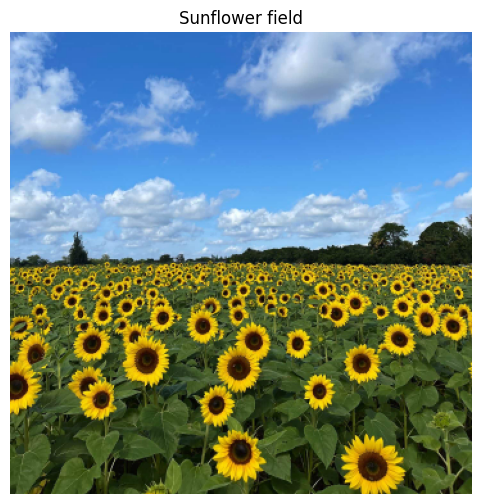

In [8]:
q1_bgr = cv2.imread(
    str(IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"),
    cv2.IMREAD_REDUCED_COLOR_4
)

if q1_bgr is None:
    raise ValueError("Could not read the sunflower image.")

q1_rgb = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2RGB)
q1_gray = cv2.cvtColor(q1_bgr, cv2.COLOR_BGR2GRAY)

print("Image shape:", q1_rgb.shape)

plt.figure(figsize=(6, 6))
plt.imshow(q1_rgb)
plt.title("Sunflower field")
plt.axis("off")
plt.show()